# Figure 7g. ABCA1 cis-eQTL and glial trans-eProgram QTL at the chr9 AD locus

Stacked locus plots of the chr9 *ABCA1* region (~104.6-105.2 Mb): AD GWAS, *ABCA1* *cis*-eQTL in anterior caudate (AC) and posterior cingulate cortex (PCC), the astrocyte *trans*-eProgram QTL (Program 464) and the microglia *trans*-eProgram QTL (Program 42). The y-axis is -log10 marginal p; blue points are the two variants of the ColocBoost colocalization set shared by all five traits (top variant chr9:104898848:C:A). The printed table gives the *ABCA1* -> *trans*-eProgram mediation (indirect) effects found in the source results file (donor-bootstrap, lead SNP chr9:104904866:T:C), with both the 85% CI used in the source plot and the 95% CI; the `figure_annotation` column is the text printed on the published figure, which does not match the values in this file (see caveats in the report).

Input: `data/Figure_7g_ABCA1_locus.rds`

In [1]:
library(ggplot2)
library(patchwork)
dat <- readRDS("data/Figure_7g_ABCA1_locus.rds")
loc <- dat$locus
head(loc)
## variants per trait and number highlighted in each colocalized set (CoS)
table(loc$trait, ifelse(is.na(loc$cos), "background", loc$cos))
dat$genes[dat$genes$in_figure, ]
## ABCA1 cis -> trans-eProgram indirect effects (source table) vs. figure annotation
dat$mediation

,trait,variant,position,neg_log10_p,cos,cos_colour
,<fct>,<chr>,<dbl>,<dbl>,<chr>,<chr>
1,Alzheimer's disease GWAS,chr9:104583177:T:C,104583177,0.01104503,NA,NA
2,Alzheimer's disease GWAS,chr9:104583306:C:T,104583306,0.01701234,NA,NA
3,Alzheimer's disease GWAS,chr9:104583657:G:A,104583657,0.13943315,NA,NA
4,Alzheimer's disease GWAS,chr9:104584892:G:A,104584892,0.01835463,NA,NA
5,Alzheimer's disease GWAS,chr9:104584929:C:A,104584929,0.22623073,NA,NA
6,Alzheimer's disease GWAS,chr9:104585114:C:T,104585114,0.19382824,NA,NA


                                             
                                              background cos1
  Alzheimer's disease GWAS                          1699    2
  AC ABCA1 cis-eQTL                                 1699    2
  PCC ABCA1 cis-eQTL                                1699    2
  Astrocytes trans-eProgram QTL (Program 464)       1699    2
  Microglia trans-eProgram QTL (Program 42)         1699    2

,gene,chrom,start,end,strand,in_figure,highlight
,<chr>,<chr>,<int>,<int>,<chr>,<lgl>,<lgl>
5,NIPSNAP3A,chr9,104747683,104760120,+,TRUE,FALSE
6,NIPSNAP3B,chr9,104764129,104777764,+,TRUE,FALSE
7,ABCA1,chr9,104781006,104928155,-,TRUE,TRUE


mediator,outcome,lead_snp,indirect_effect,ci85_lower,ci85_upper,ci95_lower,ci95_upper,bootstrap_p,BH_q_global,n_complete,figure_annotation
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<chr>
ABCA1 (AC),Ast trans-eProgram (Program 464),chr9:104904866:T:C,0.03943675,0.001077960,0.07913029,-0.009908017,0.10118577,0.1298701,0.8334523,311,"0.0692 [0.0066, 0.1327]"
ABCA1 (PCC),Mic trans-eProgram (Program 42),chr9:104904866:T:C,0.02578099,-0.001564469,0.05945846,-0.010819497,0.07463926,0.1918082,0.8334523,202,"0.0557 [0.0030, 0.1121]"


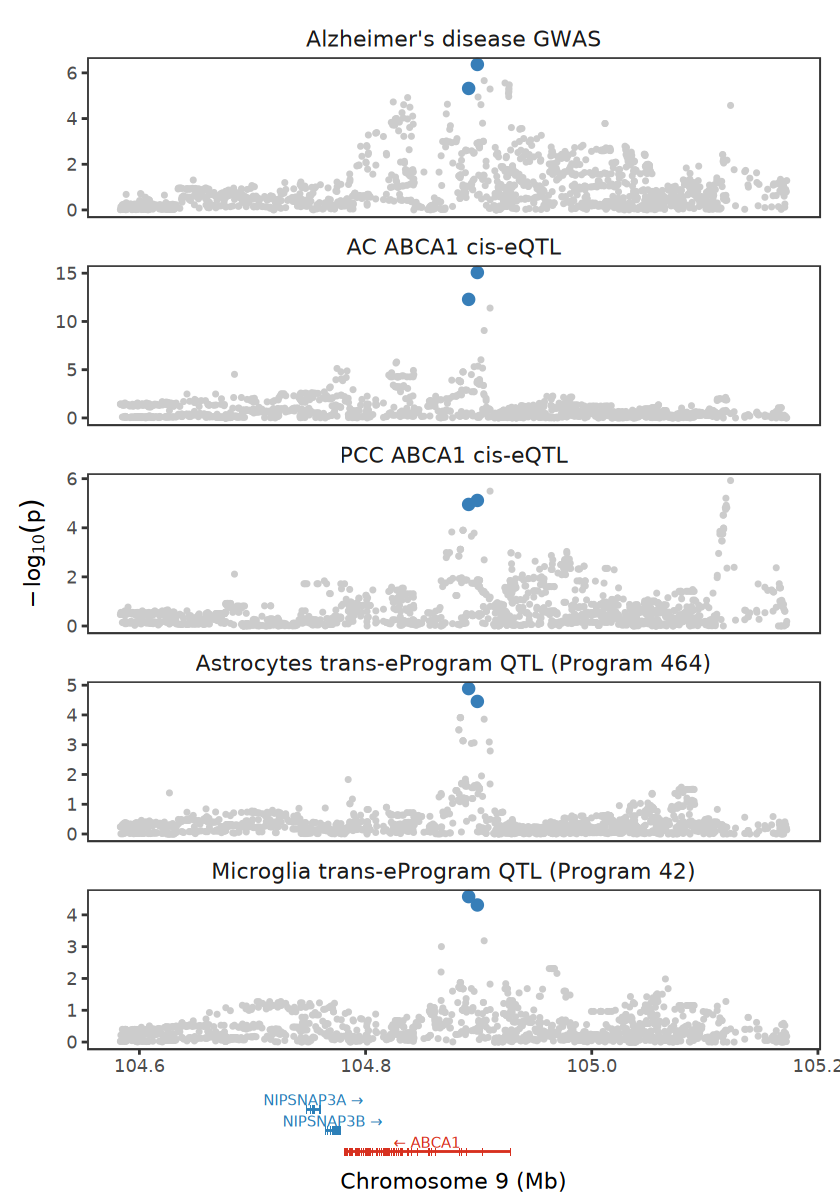

In [2]:

locus_plot <- function(dat, chrom_label, track_height = 1, annot = NULL) {
  loc  <- dat$locus
  xlim <- range(loc$position) / 1e6
  bg <- loc[is.na(loc$cos), ]
  fg <- loc[!is.na(loc$cos), ]
  cos_pal <- unique(fg[, c("cos", "cos_colour")])
  cos_pal <- setNames(cos_pal$cos_colour, cos_pal$cos)

  p_loc <- ggplot() +
    geom_point(data = bg, aes(position / 1e6, neg_log10_p), colour = "grey80", size = 0.8) +
    geom_point(data = fg, aes(position / 1e6, neg_log10_p, colour = cos), size = 2.6) +
    scale_colour_manual(values = cos_pal, guide = "none") +
    facet_wrap(~trait, ncol = 1, scales = "free_y") +
    coord_cartesian(xlim = xlim) +
    labs(x = NULL, y = expression(-log[10](p))) +
    theme_bw(base_size = 13) +
    theme(panel.grid = element_blank(), strip.background = element_blank(),
          strip.text = element_text(size = 13))
  if (!is.null(annot)) p_loc <- p_loc + annot

  ## gene track: only genes drawn in the published panel, packed into rows
  genes <- dat$genes[dat$genes$in_figure, ]
  genes <- genes[order(genes$start), ]
  pad <- diff(xlim) * 1e6 * 0.08
  row_end <- numeric(0); genes$row <- NA
  for (i in seq_len(nrow(genes))) {
    r <- which(row_end < genes$start[i] - pad)[1]
    if (is.na(r)) r <- length(row_end) + 1
    row_end[r] <- genes$end[i]; genes$row[i] <- r
  }
  genes$label <- ifelse(genes$strand == "+", paste0(genes$gene, " →"), paste0("← ", genes$gene))
  exons <- dat$exons[dat$exons$gene %in% genes$gene, ]
  exons$row <- genes$row[match(exons$gene, genes$gene)]
  exons$highlight <- genes$highlight[match(exons$gene, genes$gene)]
  hl <- c(`TRUE` = "#D7301F", `FALSE` = "#2C7FB8")

  p_gene <- ggplot(genes) +
    geom_segment(aes(x = start / 1e6, xend = end / 1e6, y = -row, yend = -row, colour = highlight),
                 linewidth = 0.6) +
    geom_rect(data = exons, aes(xmin = start / 1e6, xmax = end / 1e6, ymin = -row - 0.18,
                                ymax = -row + 0.18, fill = highlight)) +
    geom_text(aes(x = (start + end) / 2e6, y = -row + 0.45, label = label, colour = highlight), size = 3) +
    scale_colour_manual(values = hl, guide = "none") +
    scale_fill_manual(values = hl, guide = "none") +
    scale_y_continuous(expand = expansion(add = c(0.4, 0.7))) +
    coord_cartesian(xlim = xlim) +
    labs(x = chrom_label) +
    theme_void(base_size = 13) +
    theme(axis.title.x = element_text(margin = margin(t = 4)))

  p_loc / p_gene + plot_layout(heights = c(nlevels(loc$trait), track_height))
}

p <- locus_plot(dat, "Chromosome 9 (Mb)", track_height = 0.4)
options(repr.plot.width = 7, repr.plot.height = 10)
p